# 02 Results: forecasts, errors and airflow

This notebook turns the result tables from `main.py` into figures for the report. Nothing new is trained here except the linear model with monthly retraining (about 1 second), which is re-run so one test week can be plotted block by block.

Run `python main.py` (the full run, not `--quick`) from the repository root first.

Figures are saved to `reports/figures/` (fig5 onwards; fig1 to fig4 come from notebook 01).

In [1]:
import os
from pathlib import Path

# Work from the repository root so paths match main.py
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from occupancy.features import make_features, split_by_date
from occupancy.models import forecast_monthly_retrain, forecast_rolling_profile

FIGURES = Path("reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
TEST_START = "2025-03-03"

# Colours (validated colour-blind-safe set) and plain styling, same as notebook 01
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 11,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.6, "legend.frameon": False,
})

# Plain names for the methods, in the order they appear in tables and figures
NAMES = {
    "always_empty": "Always empty",
    "last_week": "Same time last week",
    "fixed_profile": "Fixed weekly profile",
    "rolling_profile": "Rolling 4-week profile",
    "linear": "Linear regression",
    "tree_depth6": "Decision tree (depth 6)",
    "mlp_64_32": "Neural network (64, 32)",
    "linear_monthly": "Linear, retrained monthly",
    "tree_depth6_monthly": "Tree, retrained monthly",
    "mlp_64_32_monthly": "Neural network, retrained monthly",
}
GROUP = {m: "Baseline" for m in ["always_empty", "last_week", "fixed_profile", "rolling_profile"]}
GROUP.update({m: "Trained once" for m in ["linear", "tree_depth6", "mlp_64_32"]})
GROUP.update({m: "Retrained monthly" for m in ["linear_monthly", "tree_depth6_monthly", "mlp_64_32_monthly"]})
GROUP_COLOUR = {"Baseline": MUTED, "Trained once": BLUE, "Retrained monthly": AQUA}

## 1. Results table (test period, 3 Mar 2025 to 21 Apr 2026)

- **MAE**: average size of the error, in people.
- **RMSE**: like MAE but punishes big misses more.
- **Bias**: average of forecast minus actual (positive = forecasts too high).
- **Peak error**: average miss on the busiest block of each day.
- **Under / over supply**: person-hours per day the forecast was below / above the real headcount (under = room short of fresh air, over = wasted air).

In [2]:
results = pd.read_csv("reports/model_results.csv", index_col=0)
missing = [m for m in NAMES if m not in results.index]
if missing:
    print("Not in model_results.csv (was main.py run with --quick?):", missing)
results = results.loc[[m for m in NAMES if m in results.index]]

table = results[["mae", "rmse", "bias", "peak_error",
                 "under_supply_ph_per_day", "over_supply_ph_per_day", "train_seconds"]].copy()
table.index = [NAMES[m] for m in table.index]
table.columns = ["MAE", "RMSE", "Bias", "Peak error", "Under (ph/day)", "Over (ph/day)", "Train time (s)"]
table.round(3)

,MAE,RMSE,Bias,Peak error,Under (ph/day),Over (ph/day),Train time (s)
Always empty,0.508,0.974,-0.508,2.869,12.183,0.000,NaN
Same time last week,0.551,0.917,0.004,1.397,6.562,6.654,NaN
Fixed weekly profile,0.658,0.984,0.315,1.294,4.113,11.664,NaN
Rolling 4-week profile,0.491,0.775,0.008,1.337,5.794,5.989,NaN
Linear regression,0.504,0.739,0.122,1.353,4.585,7.500,0.046
Decision tree (depth 6),0.543,0.842,0.145,1.334,4.768,8.257,0.117
"Neural network (64, 32)",0.552,0.952,0.142,1.462,4.911,8.330,29.106
"Linear, retrained monthly",0.478,0.718,0.071,1.409,4.875,6.589,1.136
"Tree, retrained monthly",0.502,0.771,0.095,1.482,4.886,7.164,2.134
"Neural network, retrained monthly",0.488,0.806,0.069,1.449,5.035,6.683,530.037


## 2. Error of every method

Lower is better. The dashed line is the best baseline (rolling 4-week profile), so anything left of it beats the simplest sensible method.

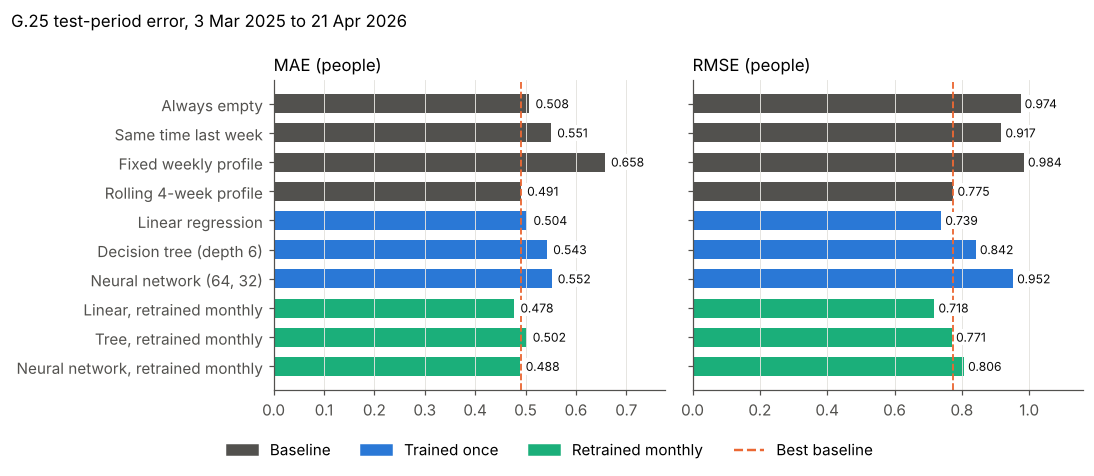

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
order = results.index[::-1]   # first method at the top
labels = [NAMES[m] for m in order]
colours = [GROUP_COLOUR[GROUP[m]] for m in order]

for ax, metric, title in zip(axes, ["mae", "rmse"], ["MAE (people)", "RMSE (people)"]):
    values = results.loc[order, metric]
    ax.barh(labels, values, color=colours, height=0.65)
    ax.axvline(results.loc["rolling_profile", metric], color=ORANGE, linestyle="--", linewidth=1.2)
    for y, v in enumerate(values):
        ax.text(v + 0.012, y, f"{v:.3f}", va="center", fontsize=8, color=INK,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
    ax.set_xlim(0, values.max() * 1.18)
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLOUR.values()]
handles.append(plt.Line2D([0], [0], color=ORANGE, linestyle="--"))
fig.legend(handles, [*GROUP_COLOUR, "Best baseline"], loc="lower center", ncol=4,
           bbox_to_anchor=(0.5, -0.02))
fig.suptitle("G.25 test-period error, 3 Mar 2025 to 21 Apr 2026", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIGURES / "fig5_method_comparison.png", bbox_inches="tight")
plt.show()

## 3. One test week, block by block

The busiest week of the test period (Mon 1 to Sun 7 Sep 2025, semester 2 teaching). Shows what the numbers above look like in practice: the real headcount, the best baseline and the best model. Both forecasts are made day-ahead, using only data up to the day before.

In [4]:
series = pd.read_parquet("data/processed/G25_15min.parquet")["headcount"]
features = make_features(series)
_, test = split_by_date(features, TEST_START)

rolling = forecast_rolling_profile(test)
linear_monthly, seconds = forecast_monthly_retrain("linear", features, TEST_START)
print(f"Linear model retrained for every test month in {seconds:.1f} s")

# Check this re-run matches the saved result
mae = (linear_monthly.reindex(test.index) - test["headcount"]).abs().mean()
print(f"MAE recomputed: {mae:.3f}  (model_results.csv: {results.loc['linear_monthly', 'mae']:.3f})")

Linear model retrained for every test month in 1.7 s
MAE recomputed: 0.478  (model_results.csv: 0.478)


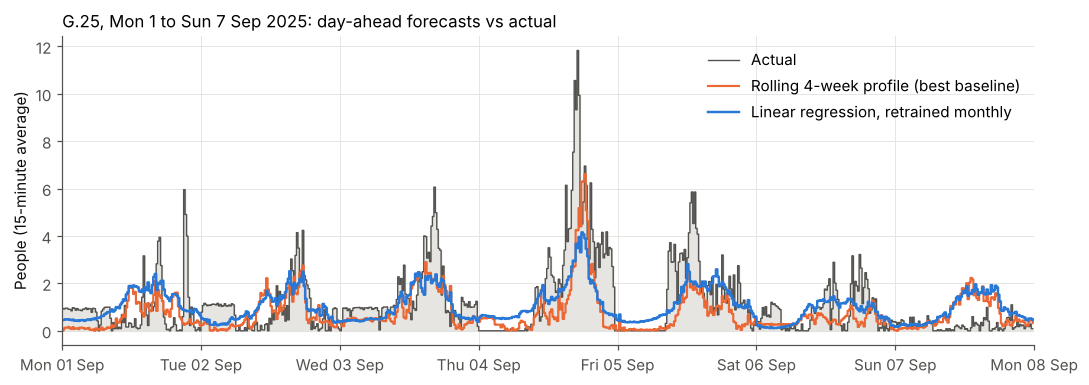

In [5]:
week = slice("2025-09-01", "2025-09-07")
actual = test["headcount"][week]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(actual.index, actual.to_numpy(), step="post", color=GRID, alpha=0.9)
ax.step(actual.index, actual.to_numpy(), where="post", color=MUTED, linewidth=0.9, label="Actual")
ax.step(rolling[week].index, rolling[week].to_numpy(), where="post", color=ORANGE,
        linewidth=1.4, label="Rolling 4-week profile (best baseline)")
ax.step(linear_monthly[week].index, linear_monthly[week].to_numpy(), where="post", color=BLUE,
        linewidth=1.6, label="Linear regression, retrained monthly")
days = pd.date_range("2025-09-01", "2025-09-08", freq="D", tz=actual.index.tz)
ax.set_xticks(days, [d.strftime("%a %d %b") for d in days])
ax.set_xlim(days[0], days[-1])
ax.set_ylabel("People (15-minute average)")
ax.set_title("G.25, Mon 1 to Sun 7 Sep 2025: day-ahead forecasts vs actual", loc="left")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIGURES / "fig6_test_week_forecast.png")
plt.show()

## 4. How the headcount is distributed, and error where it matters

The headcount is far from a bell curve: most 15-minute blocks are empty or nearly empty, with a long tail of busy blocks. So the overall average error is dominated by easy, near-empty blocks, which flatters "always empty". The table below also scores the methods only where the forecast matters most: blocks with at least one person present, and weekday working hours.

Test-period blocks: 39,844
Exactly empty: 32.9%   under 0.25 people: 58.0%   1+ person: 18.0%   3+ people: 2.1%
Median 0.14, mean 0.51, 90th percentile 1.38, max 11.8 people


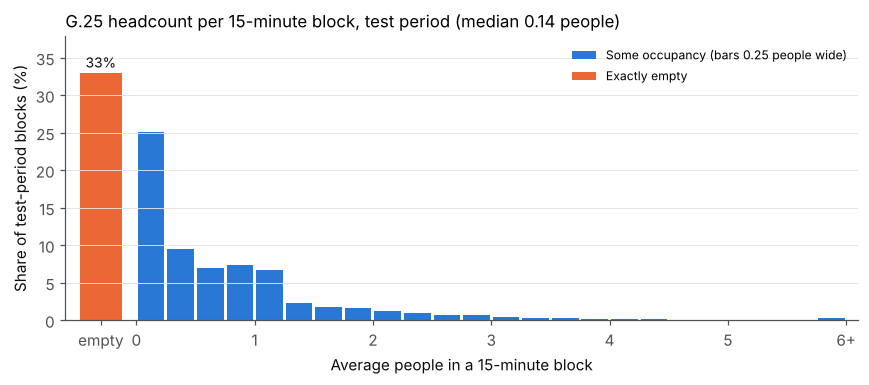

In [6]:
y = test["headcount"]
print(f"Test-period blocks: {len(y):,}")
print(f"Exactly empty: {(y == 0).mean():.1%}   under 0.25 people: {(y < 0.25).mean():.1%}   "
      f"1+ person: {(y >= 1).mean():.1%}   3+ people: {(y >= 3).mean():.1%}")
print(f"Median {y.median():.2f}, mean {y.mean():.2f}, 90th percentile {y.quantile(0.9):.2f}, max {y.max():.1f} people")

fig, ax = plt.subplots(figsize=(8, 3.6))
width = 0.25
edges = np.arange(0, 6 + width, width)          # 0-0.25, 0.25-0.5, ... ; blocks above 6 go in the last bar
positive = y[y > 0].clip(upper=6 - 1e-9)
counts, _ = np.histogram(positive, bins=edges)
ax.bar(edges[:-1] + width / 2, 100 * counts / len(y), width=width * 0.9, color=BLUE,
       label="Some occupancy (bars 0.25 people wide)")
ax.bar(-0.3, 100 * (y == 0).mean(), width=0.35, color=ORANGE, label="Exactly empty")
ax.text(-0.3, 100 * (y == 0).mean() + 0.8, f"{(y == 0).mean():.0%}", ha="center", color=INK, fontsize=9)
ax.set_xlim(-0.6, 6.1)
ax.set_ylim(0, 100 * (y == 0).mean() * 1.15)
ax.set_xticks([-0.3, 0, 1, 2, 3, 4, 5, 6], ["empty", "0", "1", "2", "3", "4", "5", "6+"])
ax.set_xlabel("Average people in a 15-minute block")
ax.set_ylabel("Share of test-period blocks (%)")
ax.set_title(f"G.25 headcount per 15-minute block, test period (median {y.median():.2f} people)", loc="left")
ax.legend(loc="upper right", fontsize=8)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIGURES / "fig9_headcount_distribution.png")
plt.show()

In [7]:
idx = test.index
groups = {
    "All blocks": np.ones(len(idx), dtype=bool),
    "1+ person present": (y >= 1).to_numpy(),
    "Weekdays 8am to 6pm": ((idx.dayofweek < 5) & (idx.hour >= 8) & (idx.hour < 18)),
    "Nights and weekends": ~((idx.dayofweek < 5) & (idx.hour >= 8) & (idx.hour < 18)),
}
forecasts = {
    "Always empty": pd.Series(0.0, index=idx),
    "Rolling 4-week profile": rolling.reindex(idx),
    "Linear, retrained monthly": linear_monthly.reindex(idx),
}
rows = {}
for name, f in forecasts.items():
    err = f - y
    ok = err.notna().to_numpy()
    rows[name] = {f"MAE, {g.lower()}": err[ok & m].abs().mean() for g, m in groups.items()}
    rows[name]["RMSE, weekdays 8am to 6pm"] = np.sqrt((err[ok & groups["Weekdays 8am to 6pm"]] ** 2).mean())
conditional = pd.DataFrame(rows).T
conditional.round(3)

,"MAE, all blocks","MAE, 1+ person present","MAE, weekdays 8am to 6pm","MAE, nights and weekends","RMSE, weekdays 8am to 6pm"
Always empty,0.508,1.867,0.888,0.346,1.403
Rolling 4-week profile,0.491,1.086,0.739,0.386,1.052
"Linear, retrained monthly",0.478,0.908,0.721,0.374,0.963


## 5. Error by year and academic period

Same scores, split up. Shows where each method does well or badly. In quiet periods (breaks, exams) the room is often empty, so "always empty" is hard to beat there.

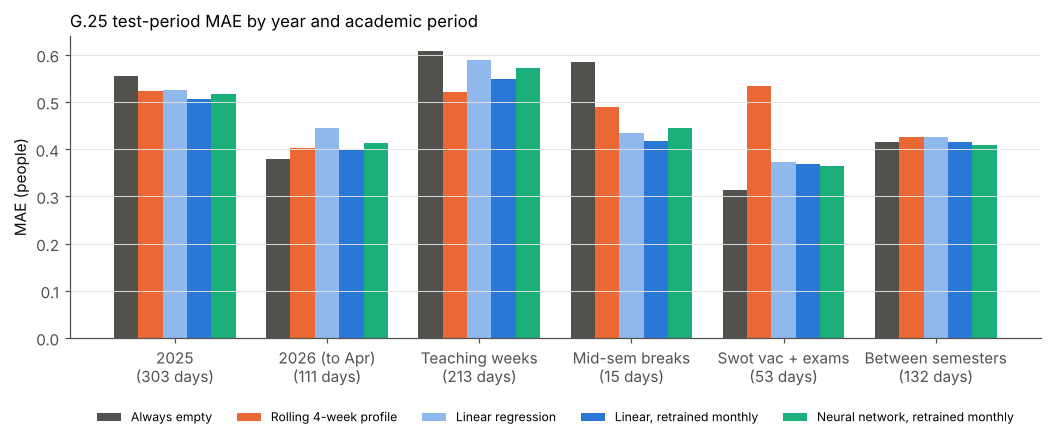

method,Always empty,Rolling 4-week profile,Linear regression,"Linear, retrained monthly","Neural network, retrained monthly"
group,,,,,
2025,0.555,0.523,0.526,0.507,0.516
2026 (to Apr),0.379,0.403,0.444,0.399,0.412
Teaching weeks,0.609,0.521,0.589,0.549,0.571
Mid-sem breaks,0.585,0.490,0.435,0.417,0.445
Swot vac + exams,0.314,0.533,0.372,0.368,0.365
Between semesters,0.414,0.426,0.426,0.414,0.410


In [8]:
by_period = pd.read_csv("reports/model_results_by_period.csv")
show = ["always_empty", "rolling_profile", "linear", "linear_monthly", "mlp_64_32_monthly"]
show = [m for m in show if m in set(by_period["method"])]
group_names = {
    "year_2025": "2025", "year_2026": "2026 (to Apr)",
    "period_teaching": "Teaching weeks", "period_midsem_break": "Mid-sem breaks",
    "period_swot_exams": "Swot vac + exams", "period_break": "Between semesters",
}
pivot = (by_period[by_period["method"].isin(show)]
         .pivot(index="group", columns="method", values="mae")
         .reindex(index=list(group_names), columns=show))
counts = by_period.drop_duplicates("group").set_index("group")["blocks_scored"]

fig, ax = plt.subplots(figsize=(10, 4.2))
colours = [MUTED, ORANGE, "#8fb9ec", BLUE, AQUA]
width = 0.8 / len(show)
x = np.arange(len(pivot))
for i, method in enumerate(show):
    ax.bar(x + (i - (len(show) - 1) / 2) * width, pivot[method], width,
           color=colours[i], label=NAMES[method])
ax.set_xticks(x, [f"{group_names[g]}\n({int(counts[g] / 96)} days)" for g in pivot.index])
ax.set_ylabel("MAE (people)")
ax.set_title("G.25 test-period MAE by year and academic period", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=5, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "fig7_error_by_period.png")
plt.show()

(pivot.rename(index=group_names, columns=NAMES)).round(3)

## 6. What the forecasts mean for fresh air

Each forecast converted to outdoor-air flow at the rate set in `main.py` (`LITRES_PER_PERSON`, L/s per person), then compared with the airflow the real headcount needed.

- **Short of air**: cubic metres per day the forecast supplied less than needed (comfort and air-quality risk).
- **Wasted air**: cubic metres per day supplied but not needed (wasted fan and conditioning energy).

The ideal point is the bottom-left corner. No method gets both to zero, so this is a trade-off.

Rate used: 10 L/s per person; real need averaged 5.1 L/s, peak 118 L/s


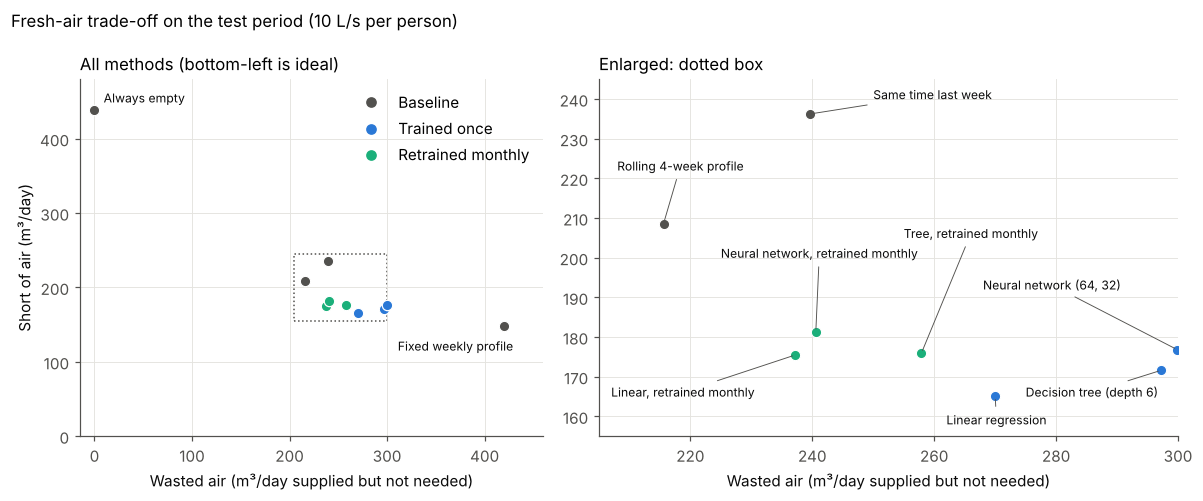

,Short (m³/day),Wasted (m³/day),Share of blocks short by 1+ person
Always empty,438.584,0.000,0.180
Same time last week,236.235,239.562,0.084
Fixed weekly profile,148.073,419.893,0.042
Rolling 4-week profile,208.598,215.600,0.068
Linear regression,165.044,270.005,0.051
Decision tree (depth 6),171.632,297.249,0.050
"Neural network (64, 32)",176.810,299.889,0.051
"Linear, retrained monthly",175.494,237.218,0.055
"Tree, retrained monthly",175.909,257.891,0.053
"Neural network, retrained monthly",181.247,240.576,0.052


In [9]:
airflow = pd.read_csv("reports/airflow_results.csv", index_col=0)
rate = airflow["litres_per_person"].iloc[0]
print(f"Rate used: {rate} L/s per person; real need averaged {airflow['mean_required_ls'].iloc[0]:.1f} L/s, "
      f"peak {airflow['peak_required_ls'].iloc[0]:.0f} L/s")

fig, (ax_all, ax_zoom) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
x_col, y_col = "over_supply_m3_per_day", "under_supply_m3_per_day"
zoom_x, zoom_y = (205, 300), (155, 245)   # the crowded middle, shown enlarged on the right

for ax in (ax_all, ax_zoom):
    for method, row in airflow.iterrows():
        ax.scatter(row[x_col], row[y_col], s=46, color=GROUP_COLOUR[GROUP[method]],
                   edgecolor="white", linewidth=0.8, zorder=3)
    ax.set_xlabel("Wasted air (m³/day supplied but not needed)")

# Left: everything. Label only the points outside the zoom box.
for method, row in airflow.iterrows():
    inside = zoom_x[0] <= row[x_col] <= zoom_x[1] and zoom_y[0] <= row[y_col] <= zoom_y[1]
    if not inside:
        ax_all.annotate(NAMES[method], (row[x_col], row[y_col]), textcoords="offset points",
                        xytext=(6, 5) if row[x_col] < 300 else (6, -16), fontsize=8,
                        ha="left" if row[x_col] < 300 else "right", color=INK)
ax_all.add_patch(plt.Rectangle((zoom_x[0], zoom_y[0]), zoom_x[1] - zoom_x[0], zoom_y[1] - zoom_y[0],
                               fill=False, edgecolor=MUTED, linestyle=":", linewidth=1))
ax_all.set_xlim(-15, 460)
ax_all.set_ylim(0, 480)
ax_all.set_ylabel("Short of air (m³/day)")
ax_all.set_title("All methods (bottom-left is ideal)", loc="left")

# Right: enlarged middle, every point labelled with a short leader line
label_at = {   # label position in data units, chosen by hand so labels don't overlap
    "last_week": (250, 240), "rolling_profile": (208, 222),
    "linear_monthly": (207, 165), "mlp_64_32_monthly": (225, 200),
    "tree_depth6_monthly": (255, 205), "linear": (262, 158),
    "tree_depth6": (275, 165), "mlp_64_32": (268, 192),
}
for method, row in airflow.iterrows():
    if method in label_at:
        ax_zoom.annotate(NAMES[method], (row[x_col], row[y_col]), xytext=label_at[method],
                         fontsize=8, color=INK,
                         arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.6))
ax_zoom.set_xlim(*zoom_x)
ax_zoom.set_ylim(*zoom_y)
ax_zoom.set_title("Enlarged: dotted box", loc="left")

handles = [plt.Line2D([0], [0], marker="o", linestyle="", color=c) for c in GROUP_COLOUR.values()]
ax_all.legend(handles, list(GROUP_COLOUR), loc="upper right")
fig.suptitle(f"Fresh-air trade-off on the test period ({rate:g} L/s per person)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "fig8_airflow_tradeoff.png")
plt.show()

cols = ["under_supply_m3_per_day", "over_supply_m3_per_day", "blocks_under_by_1_person"]
out = airflow[cols].rename(index=NAMES, columns={
    "under_supply_m3_per_day": "Short (m³/day)", "over_supply_m3_per_day": "Wasted (m³/day)",
    "blocks_under_by_1_person": "Share of blocks short by 1+ person"})
out.round(3)

## 7. Sensitivity to the cleaning assumptions

Each row changes one cleaning choice and reruns the best baseline and the linear models. If the ranking stays the same, the conclusion does not depend on that choice.

In [10]:
sens = pd.read_csv("reports/sensitivity_results.csv")
sens.pivot_table(index="case", columns="method", values="mae", sort=False).round(3)

method,rolling_profile,linear,linear_monthly
case,,,
"main settings (15 min, mean, 1 h dropout)",0.491,0.504,0.478
"block value = maximum, not average",1.060,1.038,1.002
dropout limit 30 min,0.488,0.502,0.476
dropout limit 2 h,0.493,0.505,0.479
overnight (1am to 5am) set to 0,0.446,0.472,0.444
hourly blocks instead of 15 min,0.437,0.451,0.425


## 8. Speed and memory (from `benchmark.py`)

Run `python benchmark.py` first. Times depend on the computer.

In [11]:
perf_path = Path("reports/performance.csv")
if perf_path.exists():
    perf = pd.read_csv(perf_path)
    keep = [c for c in ["step", "variant", "seconds", "peak_memory_mb", "speedup",
                        "est_flops", "achieved_gflops", "intensity_flops_per_byte"] if c in perf]
    display(perf[keep].round(3))
else:
    print("reports/performance.csv not found: run python benchmark.py")

,step,variant,seconds,peak_memory_mb,speedup,est_flops,achieved_gflops,intensity_flops_per_byte
0,load CSV,"chunks of 100,000 rows",14.217,NaN,NaN,NaN,NaN,NaN
1,load CSV,"chunks of 1,000,000 rows",13.033,NaN,NaN,NaN,NaN,NaN
2,event to 15-min grid,vectorised (pandas),0.338,185.672,NaN,NaN,NaN,NaN
3,event to 15-min grid,Python loop,1.714,28.359,5.069,NaN,NaN,NaN
4,resolution,15min blocks: grid,0.308,NaN,NaN,NaN,NaN,NaN
5,resolution,15min blocks: features,0.154,NaN,NaN,NaN,NaN,NaN
6,resolution,15min blocks: train linear,0.101,NaN,NaN,NaN,NaN,NaN
7,resolution,1h blocks: grid,0.283,NaN,NaN,NaN,NaN,NaN
8,resolution,1h blocks: features,0.040,NaN,NaN,NaN,NaN,NaN
9,resolution,1h blocks: train linear,0.015,NaN,NaN,NaN,NaN,NaN
